# Model Evaluation

## Introduction

The purpose of this notebook is model building, evaluation, and optimisation. This is the 4th notebook in the project after data inspection, EDA, and preprocessing.

The goal is to predict probability scores for heart disease and recall is an especially important evaluation metric as it is of extreme importance to maximise true positives as much as possible, so the diagnosis of a patient is not missed. This may come at the cost of an increase in false positives, but this is not as harmful.

The models that will be used will be Logistic Regression, Random Forest, and XGBoost. These will be optimised using either hyperparameter tuning (RandomizedSearchCV) and threshold tuning (which should help with class imbalance), depending on which one produces the best result.

The metrics used to evaluate the models will primarily be recall as this is the most important metrics, as well as confusion matrices and classification report to support interpretations.

The deliverables for this notebook:
* Baseline model performance
* Tuned model performance
* Threshold-adjusted performance
* Final model selection based on recall comparisons and justification for the chosen model

In [1]:
#Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

##Preprocessing Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline

##Splitting Pipeline
from sklearn.model_selection import train_test_split

#Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

#Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

#Evaluation
from sklearn.metrics import accuracy_score, recall_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve

In [2]:
#Load Data
df = pd.read_csv('../Data/df_preprocess.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,age_bucket,oldpeak_threshold
0,63.0,Male,Typical Angina,145.0,233.0,True,Possible Left Ventricle Hypertrophy,150.0,No,2.3,Downsloping,0,Fixed Defect,0,Senior,High
1,67.0,Male,Asymptomatic,160.0,286.0,False,Possible Left Ventricle Hypertrophy,108.0,Yes,1.5,Flat,3,Normal,1,Senior,Medium
2,67.0,Male,Asymptomatic,120.0,229.0,False,Possible Left Ventricle Hypertrophy,129.0,Yes,2.6,Flat,2,Reversible Defect,1,Senior,High
3,37.0,Male,Non-Anginal Pain,130.0,250.0,False,Normal,187.0,No,3.5,Downsloping,0,Normal,0,Young,High
4,41.0,Female,Atypical Angina,130.0,204.0,False,Possible Left Ventricle Hypertrophy,172.0,No,1.4,Upsloping,0,Normal,0,Young,Medium


## Preprocessing Pipeline

In [3]:
##Preprocessing Pipeline

#Define numeric features that need to be scaled and categorical features that need OneHotEncoding
numeric_features = ['age','trestbps','chol','thalach','oldpeak']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope','ca','thal','age_bucket','oldpeak_threshold']

#Create a preprocessing transformer variable
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown = 'ignore'), categorical_features)
    ]
)

In [4]:
#Define target and features
X = df.drop("target", axis = 1)
y = df["target"]

#Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

#Display th shape of the data
print(f'Training set shape: {X_train.shape}')
print(f'Testing set shape: {X_test.shape}')

Training set shape: (237, 15)
Testing set shape: (60, 15)


## Logistic Regression

### Baseline

In [5]:
#Build the pipeline
pipeline_lr = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('classifier', LogisticRegression(random_state = 42, class_weight = 'balanced'))
])

#Fit pipeline onto split data
pipeline_lr.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal', 'age_bucket',
                                                   'oldpeak_threshold'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', random_state=42))])

Model Recall: 0.86
              precision    recall  f1-score   support

           0       0.87      0.84      0.86        32
           1       0.83      0.86      0.84        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



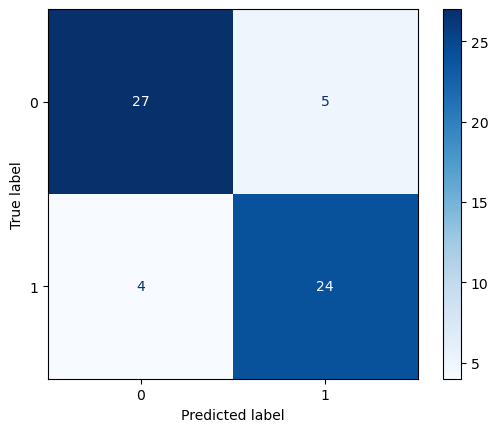

In [7]:
#Evaluate the Model
y_pred_lr = pipeline_lr.predict(X_test)

#Recall
print(f'Model Recall: {(recall_score(y_test, y_pred_lr)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_lr))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.Blues)

**Baseline Logistic Regression - Comments:**

* The baseline model recall is very high at 0.86. This is due to setting 'class_weight = 'balanced' in the pipeline, which improves recall.
* However, this could be improved for a medical screening model. This is because although 24 patients were predicted correctly, there was still 4 patients who were false negatives, which could still have a major impact on the medical care of these patients.
* Furthermore, the other metrics are all above 0.80, suggesting an overall strong model.

Hyperparameter tuning will now be carried out to try and improve recall.

### Tuned Model

In [8]:
#Define the hyperparameter search space
param_dist_lr = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100], #strength of regularisation
    'classifier__penalty': ['l2'], #type of penalty
    'classifier__class_weight': ['balanced', None], #whether to balance classes
    'classifier__solver':['lbfgs', 'saga'] #optimisation algorithm
}

#Create tuning object
random_search_lr = RandomizedSearchCV(
    estimator = pipeline_lr, #Specify to tune whole pipeline
    param_distributions = param_dist_lr, #tune based on the hyperparameters in param_dist_lr 
    n_iter = 20, #Number of random combinations to try
    scoring = 'recall', #Choose model with highest recall
    cv = 5, #Use 5-fold cross-validation
    random_state = 42,
    n_jobs = -1 #Use all CPU cores
)

#Fit the tuning process
random_search_lr.fit(X_train, y_train)

#Print the best hyperparameters
print(random_search_lr.best_params_)

{'classifier__solver': 'lbfgs', 'classifier__penalty': 'l2', 'classifier__class_weight': 'balanced', 'classifier__C': 0.1}


Model Recall: 0.79
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        32
           1       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



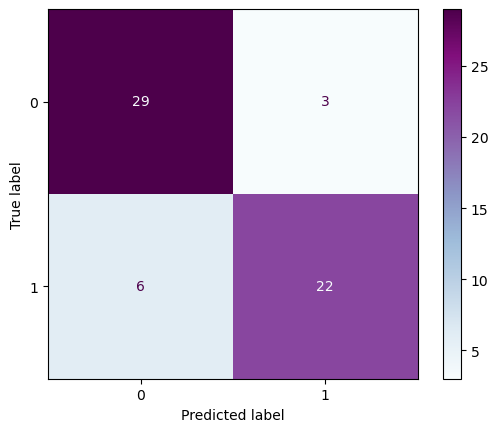

In [12]:
#Extract the best model found by RandomizedSearchCV
best_model_lr = random_search_lr.best_estimator_

#Use tuned model to make predictions on the test set
y_pred_tuned_lr = best_model_lr.predict(X_test)

#Print Recall
print(f'Model Recall: {(recall_score(y_test, y_pred_tuned_lr)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_tuned_lr))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_tuned_lr)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.BuPu)

**Tuned Logistic Regression - Comments:**
* The recall is not as good as the baseline model (0.79 vs 0.86). This suggests that this is not the best logistic regression model. This is to be expected with hyperparameter tuning as it often optimises general performance rather than one metric specifically.
  
* This is reflected in the confusion matrix. Although the number of true positives go up by 3, in comparison to the baseline (22 vs 24), the number of false negatives also go up (4 vs 6). This suggests more patients who truly have coronary artery disease are going undiagnosed, which is dangerous.

Threshold-Adjusting will now be used to see if this improves recall.

### Threshold-Adjusted Model

<function matplotlib.pyplot.show(close=None, block=None)>

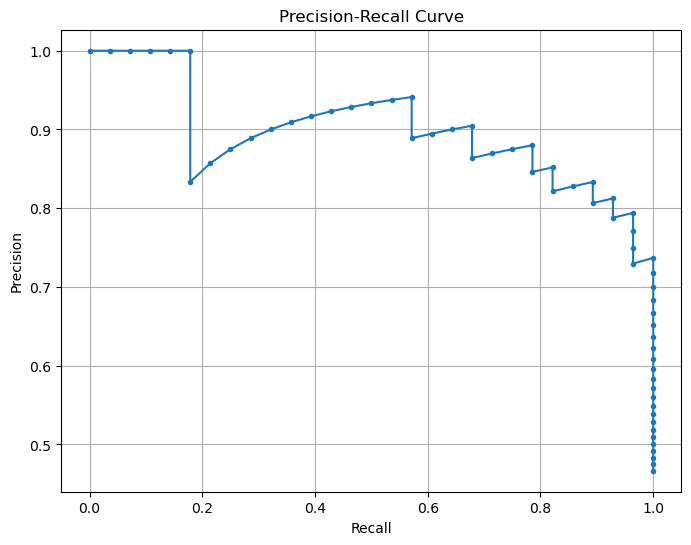

In [13]:
#Get predicted probabilities from baseline model (Note: predict_proba() returns 2 colums. 0 = probability of class 0; 1 = probability of class 1)
y_proba_lr = pipeline_lr.predict_proba(X_test)[:,1] #Select the probability in column 1

#Calculate precision-recall values across all possible thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_lr)

#Plot precision-recall curve
plt.figure(figsize = (8,6))
plt.plot(recall, precision, marker = '.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show

In [14]:
#Loop through each threshold and print recall and precision values
for r, p, t in zip(recall[:-1], precision[:-1], thresholds):  #[:-1] removes the last value so all three arrays match in length as thresholds is always one shorter 
    print(f"Threshold: {t: .3f} Recall: {r:.3f} Precision: {p: .3f}") #print results

Threshold:  0.008 Recall: 1.000 Precision:  0.467
Threshold:  0.011 Recall: 1.000 Precision:  0.475
Threshold:  0.012 Recall: 1.000 Precision:  0.483
Threshold:  0.013 Recall: 1.000 Precision:  0.491
Threshold:  0.022 Recall: 1.000 Precision:  0.500
Threshold:  0.023 Recall: 1.000 Precision:  0.509
Threshold:  0.024 Recall: 1.000 Precision:  0.519
Threshold:  0.024 Recall: 1.000 Precision:  0.528
Threshold:  0.026 Recall: 1.000 Precision:  0.538
Threshold:  0.026 Recall: 1.000 Precision:  0.549
Threshold:  0.029 Recall: 1.000 Precision:  0.560
Threshold:  0.030 Recall: 1.000 Precision:  0.571
Threshold:  0.030 Recall: 1.000 Precision:  0.583
Threshold:  0.039 Recall: 1.000 Precision:  0.596
Threshold:  0.046 Recall: 1.000 Precision:  0.609
Threshold:  0.051 Recall: 1.000 Precision:  0.622
Threshold:  0.058 Recall: 1.000 Precision:  0.636
Threshold:  0.088 Recall: 1.000 Precision:  0.651
Threshold:  0.100 Recall: 1.000 Precision:  0.667
Threshold:  0.100 Recall: 1.000 Precision:  0.683


Re-evaluated Model Recall: 1.00
              precision    recall  f1-score   support

           0       1.00      0.69      0.81        32
           1       0.74      1.00      0.85        28

    accuracy                           0.83        60
   macro avg       0.87      0.84      0.83        60
weighted avg       0.88      0.83      0.83        60



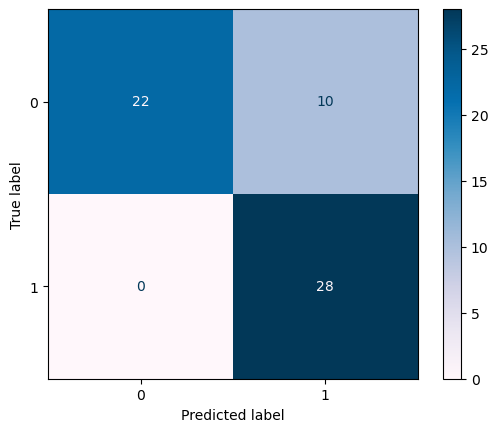

In [15]:
#Recall Improvement
#Choose threshold based on output from loop above, 0.133 achieves highest recall without reducing precision to much
threshold = 0.133

#Convert probabilities into predictions
#Check whether each probability is greater or equal to 0.133 (if 13.3% chance of the patient having heart disease => 1)
#convert boolean True and False into 0 and 1s
y_pred_threshold_lr = (y_proba_lr >= threshold).astype(int)

#Re-evaluate recall
print(f'Re-evaluated Model Recall: {(recall_score(y_test, y_pred_threshold_lr)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_threshold_lr))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_threshold_lr)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.PuBu)

**Threshold-Adjusted Logistic Regression - Comments:**

* The recall is perfect for the threshold-adjusted model at 1.0. This is the goal of the model: to be able to identify all true positives.
* Also, the confusion matrix showed 0 false negatives, suggesting no heart disease patients were missed.
* There has been a bit of a sacrifice with the precision. However, recall is the most important matrix. Therefore, we can accept that precision might be a bit lower.

This is the best logistic regression model and will be compared to the other types of models.

## Random Forest Classifier

### Baseline

In [16]:
#Build the pipeline
pipeline_rfc = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('classifier', RandomForestClassifier(random_state = 42, class_weight = 'balanced'))
])

#fit the pipeline
pipeline_rfc.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal', 'age_bucket',
                                                   'oldpeak_threshold'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

Model Recall: 0.79
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        32
           1       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



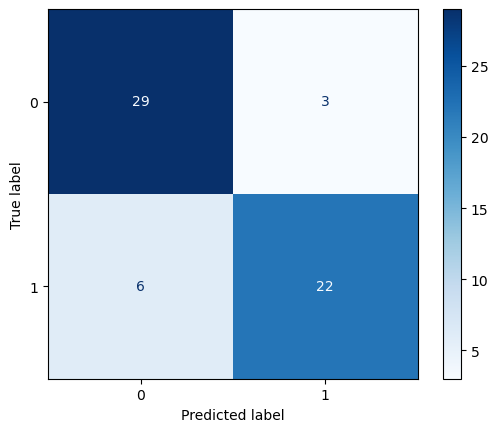

In [17]:
#Evaluate Model
y_pred_rfc = pipeline_rfc.predict(X_test)

#Print Recall
print(f'Model Recall: {(recall_score(y_test, y_pred_rfc)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_rfc))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_rfc)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.Blues)

**Random Forest Baseline - Comments:**
* The recall of the model is 0.79, which is lower than the baseline for logistic regression (0.86). This suggests that the baseline of this model is not as good at identifying patients with heart disease.
* This is also highlighted by the 6 false negatives seen in the confusion matrix.
* Therefore, in order for this model to be considered, tuning/threshold-adjusting is needed to increase the recall.

Hyperparameter Tuning is carried out next.

### Tuned Model

In [18]:
#Hyperparamter Tuning

#Define hyperparamter search space - dictionary for the hyperparameter to tune and each value for a lost of possible settings to explore
param_dist_rfc = {
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__max_depth': [None, 5, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2', None]
}

#Set up randomsearchcv to optimise for recall
random_search_rfc = RandomizedSearchCV(
    estimator = pipeline_rfc,
    param_distributions = param_dist_rfc,
    n_iter = 20,
    scoring = 'recall',
    cv = 5, #uses 5-fold cross-validation
    random_state = 42
)

#Fit the tuning process
random_search_rfc.fit(X_train, y_train)

#Print the results
print(random_search_rfc.best_params_)
print(random_search_rfc.best_score_)

{'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20}
0.8151515151515152


In [19]:
#Select the best tuned random forest model
best_model_rfc = random_search_rfc.best_estimator_

#Make predictions using the test set
y_pred_tuned_rfc = best_model_rfc.predict(X_test)

Model Recall: 0.75
              precision    recall  f1-score   support

           0       0.80      0.88      0.84        32
           1       0.84      0.75      0.79        28

    accuracy                           0.82        60
   macro avg       0.82      0.81      0.81        60
weighted avg       0.82      0.82      0.82        60



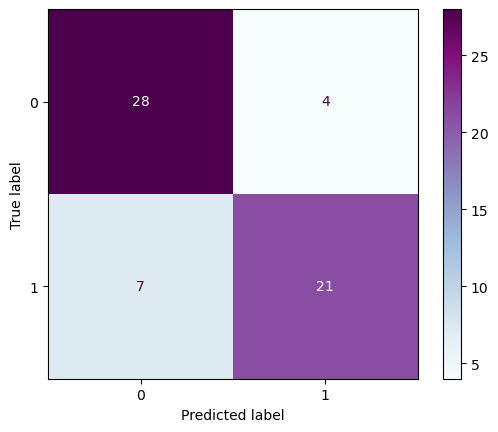

In [21]:
#Recall
print(f'Model Recall: {(recall_score(y_test, y_pred_tuned_rfc)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_tuned_rfc))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_tuned_rfc)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.BuPu)

**Tuned Random Forest Model - Comments:**
* The recall for the tuned model is 0.75, this is lower than the baseline model (0.79). Therefore, this model is not the best random forest model.
* There is also a higher amount of false negatives (7), this means there are more patients who will likely go undiagnosed which is dangerous.

Threshold-Adjusting is next to see if there is an improvement in recall.

### Threshold-Adjusted Model

<function matplotlib.pyplot.show(close=None, block=None)>

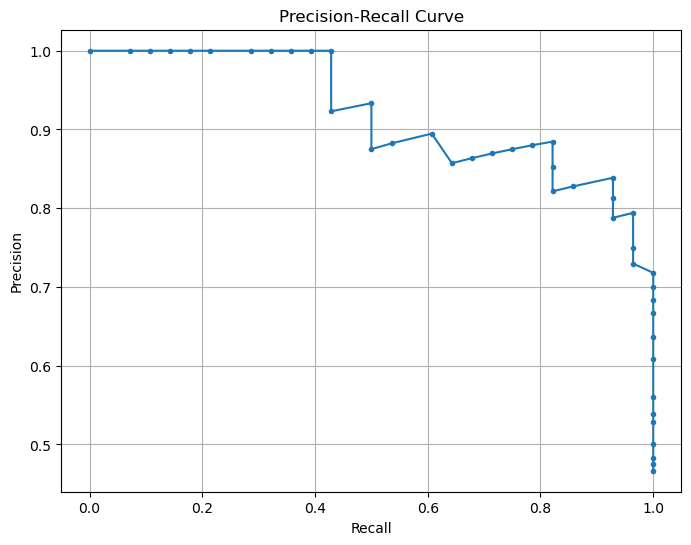

In [22]:
y_proba_rfc = pipeline_rfc.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_rfc)

plt.figure(figsize = (8,6))
plt.plot(recall, precision, marker = '.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show

In [23]:
for r, p, t in zip(recall[:-1], precision, thresholds):
    print(f"Threshold: {t: .3f} Recall: {r:.3f} Precision: {p: .3f}")

Threshold:  0.000 Recall: 1.000 Precision:  0.467
Threshold:  0.020 Recall: 1.000 Precision:  0.475
Threshold:  0.030 Recall: 1.000 Precision:  0.483
Threshold:  0.050 Recall: 1.000 Precision:  0.500
Threshold:  0.060 Recall: 1.000 Precision:  0.528
Threshold:  0.070 Recall: 1.000 Precision:  0.538
Threshold:  0.080 Recall: 1.000 Precision:  0.560
Threshold:  0.100 Recall: 1.000 Precision:  0.609
Threshold:  0.120 Recall: 1.000 Precision:  0.636
Threshold:  0.140 Recall: 1.000 Precision:  0.667
Threshold:  0.200 Recall: 1.000 Precision:  0.683
Threshold:  0.220 Recall: 1.000 Precision:  0.700
Threshold:  0.250 Recall: 1.000 Precision:  0.718
Threshold:  0.270 Recall: 0.964 Precision:  0.730
Threshold:  0.290 Recall: 0.964 Precision:  0.750
Threshold:  0.310 Recall: 0.964 Precision:  0.794
Threshold:  0.320 Recall: 0.929 Precision:  0.788
Threshold:  0.350 Recall: 0.929 Precision:  0.812
Threshold:  0.400 Recall: 0.929 Precision:  0.839
Threshold:  0.410 Recall: 0.857 Precision:  0.828


Re-evaluated Model Recall: 1.00
              precision    recall  f1-score   support

           0       1.00      0.66      0.79        32
           1       0.72      1.00      0.84        28

    accuracy                           0.82        60
   macro avg       0.86      0.83      0.81        60
weighted avg       0.87      0.82      0.81        60



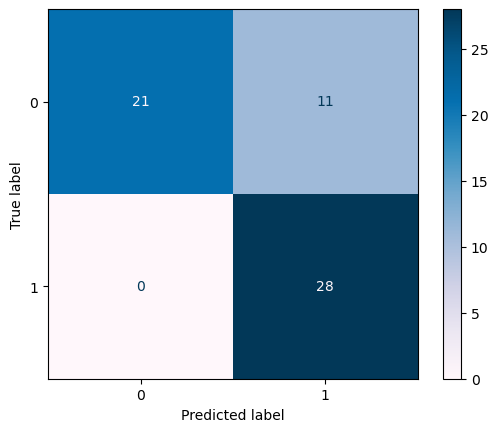

In [25]:
#Recall Improvement
threshold = 0.250
y_pred_threshold_rfc = (y_proba_rfc >= threshold).astype(int)

#Re-evaluate recall
print(f'Re-evaluated Model Recall: {(recall_score(y_test, y_pred_threshold_rfc)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_threshold_rfc))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_threshold_rfc)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.PuBu)

**Threshold Adjusted Random Forest Model - Comments:**
* The threshold adjusted model has performed the best out of the 3 random forest models. The recall of 1.00 is the highest and is extremely good for medical contexts.
* This model also has a false negative value of 0, suggesting that no patients go undiagnosed.

This is the highest performing Random Forest model and it will be compared to Logistic Regression and XGBoost.

## XGBoost

### Baseline

In [26]:
#Build the pipeline
pipeline_xgb = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('classifier', XGBClassifier(random_state = 42))
])

#Fit the pipeline
pipeline_xgb.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal', 'age_bucket',
                                                   'oldpeak_threshold'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsa...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Model Recall: 0.82
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        32
           1       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60



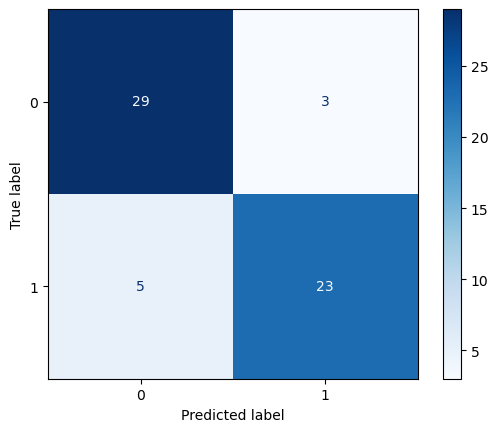

In [27]:
#Evaluate Model
y_pred_xgb = pipeline_xgb.predict(X_test)

#Recall
print(f'Model Recall: {(recall_score(y_test, y_pred_xgb)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_xgb))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_xgb)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.Blues)

**XGBoost Baseline Model - Comments:**
* The recall of the XGBoost Baseline Model is moderately good, with a value of 0.82. However, we should aim for a higher value in a medical context where an undiagnosed patient could be drastically affected.
* This is further reflected by the model having a high false negative value of 5, which is dangerous in a medical context.

Next, Hyperparamter tuning will be carried out to see if there is an improvement to recall.

### Tuned Model

In [28]:
#Hyperparamter Tuning
param_dist_xgb = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__max_depth': [3, 4, 5, 6],
    'classifier__subsample': [0.6, 0.7, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'classifier__gamma': [0, 0.1, 0.5, 1],
    'classifier__scale_pos_weight': [1, 2, 3, 5, 10]
}

random_search_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_dist_xgb,
    n_iter=25,
    scoring='recall',
    cv=5,
    random_state=42
)

random_search_xgb.fit(X_train, y_train)
print(random_search_xgb.best_params_)
print(random_search_xgb.best_estimator_)

{'classifier__subsample': 0.6, 'classifier__scale_pos_weight': 10, 'classifier__n_estimators': 300, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.01, 'classifier__gamma': 0, 'classifier__colsample_bytree': 1.0}
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal', 'age_bucket',
                                                   'oldpeak_threshold'])])),
                ('classifier',
                 XGBClassifier(b

Model Recall: 0.96
              precision    recall  f1-score   support

           0       0.96      0.72      0.82        32
           1       0.75      0.96      0.84        28

    accuracy                           0.83        60
   macro avg       0.85      0.84      0.83        60
weighted avg       0.86      0.83      0.83        60



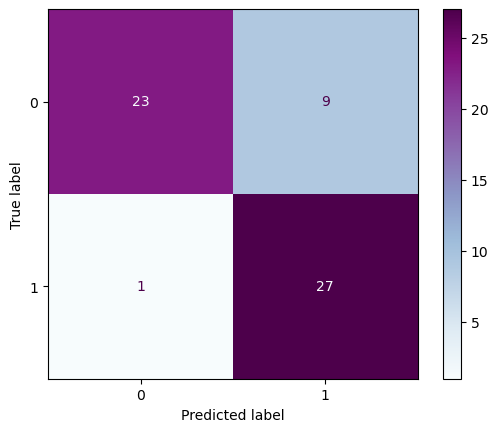

In [29]:
best_model_xgb = random_search_xgb.best_estimator_
y_pred_tuned_xgb = best_model_xgb.predict(X_test)

#Recall
print(f'Model Recall: {(recall_score(y_test, y_pred_tuned_xgb)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_tuned_xgb))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_tuned_xgb)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.BuPu)

**XGBoost Tuned Model - Comments:**
* Hyperparameter Tuning has highly improved recall from the baseline model (0.96 vs 0.82). This is good for a medical context, as it means less patients are left undiagnosed (there was only 1 false negative).
* However, the ideal outcome is a recall of 1.00, meaning no patients are missed.

Threshold-Adjusting will now be used to see if we can further optimise the recall of XGBoost.

### Threshold-Adjusted Model

<function matplotlib.pyplot.show(close=None, block=None)>

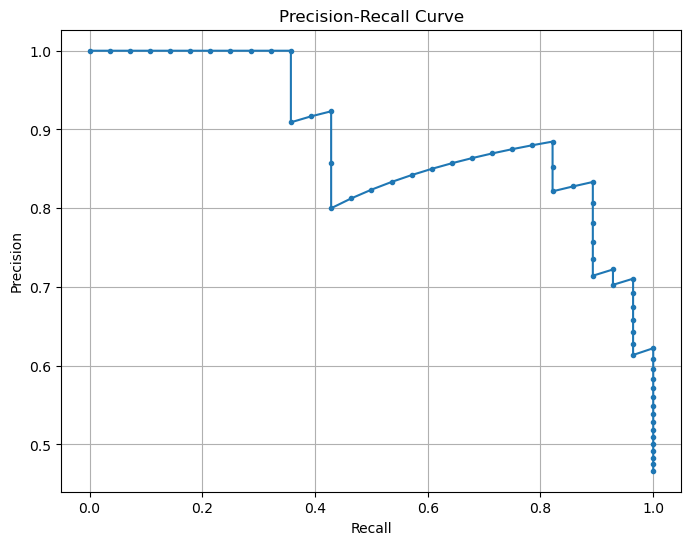

In [30]:
y_proba_threshold_xgb = pipeline_xgb.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, y_proba_threshold_xgb)

plt.figure(figsize = (8,6))
plt.plot(recall, precision, marker = '.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show

In [31]:
for r, p, t in zip(recall[:-1], precision, thresholds):
    print(f"Threshold: {t: .3f} Recall: {r:.3f} Precision: {p: .3f}")

Threshold:  0.000 Recall: 1.000 Precision:  0.467
Threshold:  0.001 Recall: 1.000 Precision:  0.475
Threshold:  0.001 Recall: 1.000 Precision:  0.483
Threshold:  0.001 Recall: 1.000 Precision:  0.491
Threshold:  0.001 Recall: 1.000 Precision:  0.500
Threshold:  0.002 Recall: 1.000 Precision:  0.509
Threshold:  0.002 Recall: 1.000 Precision:  0.519
Threshold:  0.002 Recall: 1.000 Precision:  0.528
Threshold:  0.003 Recall: 1.000 Precision:  0.538
Threshold:  0.003 Recall: 1.000 Precision:  0.549
Threshold:  0.004 Recall: 1.000 Precision:  0.560
Threshold:  0.004 Recall: 1.000 Precision:  0.571
Threshold:  0.005 Recall: 1.000 Precision:  0.583
Threshold:  0.007 Recall: 1.000 Precision:  0.596
Threshold:  0.007 Recall: 1.000 Precision:  0.609
Threshold:  0.008 Recall: 1.000 Precision:  0.622
Threshold:  0.008 Recall: 0.964 Precision:  0.614
Threshold:  0.009 Recall: 0.964 Precision:  0.628
Threshold:  0.010 Recall: 0.964 Precision:  0.643
Threshold:  0.012 Recall: 0.964 Precision:  0.659


Re-evaluated Model Recall: 1.00
              precision    recall  f1-score   support

           0       1.00      0.41      0.58        32
           1       0.60      1.00      0.75        28

    accuracy                           0.68        60
   macro avg       0.80      0.70      0.66        60
weighted avg       0.81      0.68      0.66        60



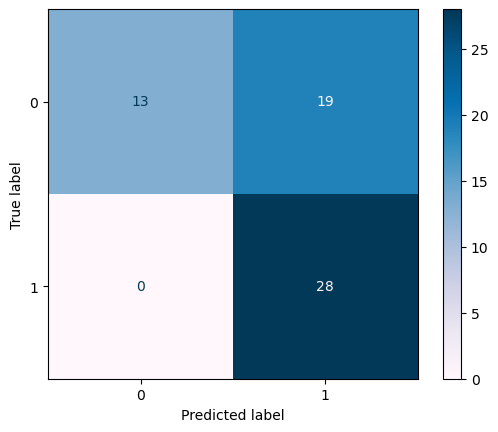

In [33]:
#Recall Improvement
threshold = 0.007
y_pred_threshold_xgb = (y_proba_threshold_xgb >= threshold).astype(int)

#Re-evaluate recall
print(f'Re-evaluated Model Recall: {(recall_score(y_test, y_pred_threshold_xgb)):.2f}')

#Print Classification Report
print(classification_report(y_test, y_pred_threshold_xgb))

#Print Confusion Matrix
cnf_matrix = confusion_matrix(y_test, y_pred_threshold_xgb)
ConfusionMatrixDisplay(confusion_matrix = cnf_matrix).plot(cmap=plt.cm.PuBu)

**XGBoost Threshold-Adjusted Model - Comments:**
* Recall has been maximised in this model (1.00), above the tuned model. This means that no patients were falsely predicted negative and all patients were correctly predicted.
* In order for recall to be fully optimised, there has been a trade-off in other metrics, in particular precision (0.88 in baseline vs 0.60 in threshold-adjusted model). However, precision should take a hit in order to avoid the drastic consequences of missing a patient with heart disease.

This is the XGBoost model that will be used in the comparison against other models.

## Model Comparison

|Model|Model Version|**Recall**|Precision|F1|Accuracy|
|-----|-------------|----------|---------|--|--------|
|Logistic Regression|Threshold-Adjusted Model|**1.00**|0.74|0.85|0.83|
|Random Forest|Threshold-Adjusted Model|**1.00**|0.72|0.84|0.82|
|XGBoost|Threshold-Adjusted Model|**1.00**|0.60|0.75|0.68|

### Model Choice
The chosen model will be threshold-adjusted logistic regression. Although, all threshold-adjusted models performed well in recall, logistic regression had a maximised recall with the lowest amount of trade-offs for precision, F1, and accuracy. 

Although recall is the primary metric in a medical screening context, secondary metrics still co ntribute to the model's overall reliability.

Furthermore, logistic regression is also considered one of the more interpretable models, which is often preferred in clinical settings.